# CMS Steepener Pricer: Replication, G2++, Quasi-Gaussian (Cheyette) and SABR-LMM

A **CMS steepener** pays a leveraged spread of two constant maturity swap rates, here fixed in advance and paid in
arrears, floored and capped, with the notional redeemed at maturity:
$$
\text{coupon}_k = \tau_k \min\Bigl(\max\bigl(L\,(S_{10}(T_{k-1}) - S_{2}(T_{k-1})) + m,\ \text{floor}\bigr),\ \text{cap}\Bigr),
\qquad \text{paid at } T_k .
$$
Two effects drive the value:
1. **Convexity**: the CMS rate paid at $T_p$ is valued under $\mathbb{Q}^{T_p}$, under which the swap rate is not a
   martingale, so $\mathbb{E}^{T_p}[S(T)] \neq S(0)$. The adjustment comes from the swaption smile (static replication).
2. **Correlation**: the floor and the cap are options on the **spread**. They depend on the joint law of $S_{10}$ and
   $S_2$, which a one-factor model cannot produce (perfect correlation).

| Section | Method | Code |
|---|---|---|
| 1-2 | Market data, curve, historical vols / correlation / PCA, volatility inputs | `eur_swap_market.py` |
| 3 | CMS convexity by static replication (linear TSR) | `Fixed_Income_Models/cms.py` |
| 4 | Market approach: replicated CMS forwards + Gaussian spread | `steepener_cms.py` |
| 5 | Hull-White 1F (baseline, perfect correlation) | `Fixed_Income_Models/hull_white_1F.py` |
| 6 | G2++ / Hull-White 2F | `Fixed_Income_Models/hull_white_2F.py` |
| 7 | 2-factor quasi-Gaussian (Cheyette) with local and stochastic vol | `Fixed_Income_Models/cheyette.py` |
| 8 | SABR-LMM (and plain LMM) | `Fixed_Income_Models/lmm.py` |
| 9-10 | Comparison, fair margin, sensitivities | `steepener_cms.py` |

> **Data limitation.** `Data/EUR/EUR_SWAP_RATES.csv` contains **par swap rates only** (1y-50y, daily, 2000 to
> 18/08/2022). It gives the curve and the *historical* dynamics, **not** swaption prices. ATM vols are therefore a
> **historical proxy** (1-year realised normal vol of the swap rate of the same tenor, flat in expiry), and the SABR
> $\rho, \nu$ are **illustrative**. The prices below illustrate the models; they are not market prices.

In [2]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..")))   # Projets : Fixed_Income_Models
sys.path.append(os.path.abspath(".."))                       # Produits : rate_products.py, rates_market.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

from Fixed_Income_Models import (CMSReplication, G2pp, QuasiGaussian, SABRLMM, HullWhite, RatePricer, SABR,
                                 forward_swap, mc_swaption_vols)
from rate_products import Swaption
from eur_swap_market import (swap_rates, eur_curve, realised_normal_vols, change_correlation, pca,
                             historical_swaption_vols, sabr_smile, VALUATION_DATE, ILLUSTRATIVE_SABR)
from steepener_cms import CMSSteepener, price_replication_copula, price_mc, simulate_cms, fair_margin

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
FIGURES = os.path.join("..", "..", "Reports", "CMS", "figures")
os.makedirs(FIGURES, exist_ok=True)

# Chart style : fixed categorical order, recessive grid and axes, 2px lines
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.prop_cycle": cycler(color=COLORS), "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold"})
MODEL_COLOR = {"Replication + Gaussian spread": MUTED, "HW1F": COLORS[7], "G2++": COLORS[0],
               "Cheyette LV": COLORS[3], "Cheyette LV+SV": COLORS[1], "LMM": COLORS[6], "SABR-LMM": COLORS[2]}

def save(fig, name):
    fig.savefig(os.path.join(FIGURES, name), dpi=150, bbox_inches="tight")

N_PATHS, SEED = 50_000, 42

def martingale_test(model, times, n_paths, seed=1):
    # E[D(0,T)] - P(0,T) and its standard error (antithetic pairs), in bp
    _, D = model.simulate(times, n_paths, seed)
    pairs = 0.5 * (D[:, :n_paths // 2] + D[:, n_paths // 2:])
    return pd.DataFrame({"error (bp)": 1e4 * (D.mean(axis=1) - model.curve.discount(times)),
                         "s.e. (bp)": 1e4 * pairs.std(axis=1, ddof=1) / np.sqrt(n_paths // 2)},
                        index=pd.Index(times, name="T")).T.round(2)

## 1. Market data

### 1.1 The swap rate history
The file repeats the last fixing on weekends: only business days are kept. Rates are in decimals and tenors in years.

In [3]:
rates = swap_rates()
print(f"{len(rates)} business days from {rates.index[0].date()} to {rates.index[-1].date()} | tenors : "
      f"{', '.join(f'{t:g}y' for t in rates.columns)}")
rates.isna().sum().rename("missing values").to_frame().T

5904 business days from 2000-01-03 to 2022-08-18 | tenors : 1y, 2y, 3y, 4y, 5y, 6y, 7y, 8y, 9y, 10y, 11y, 12y, 15y, 20y, 25y, 30y, 35y, 40y, 45y, 50y


,1,2,3,4,5,6,7,8,9,10,11,12,15,20,25,30,35,40,45,50
missing values,0,0,0,0,0,0,0,0,0,0,21,0,0,0,0,0,1166,386,1010,418


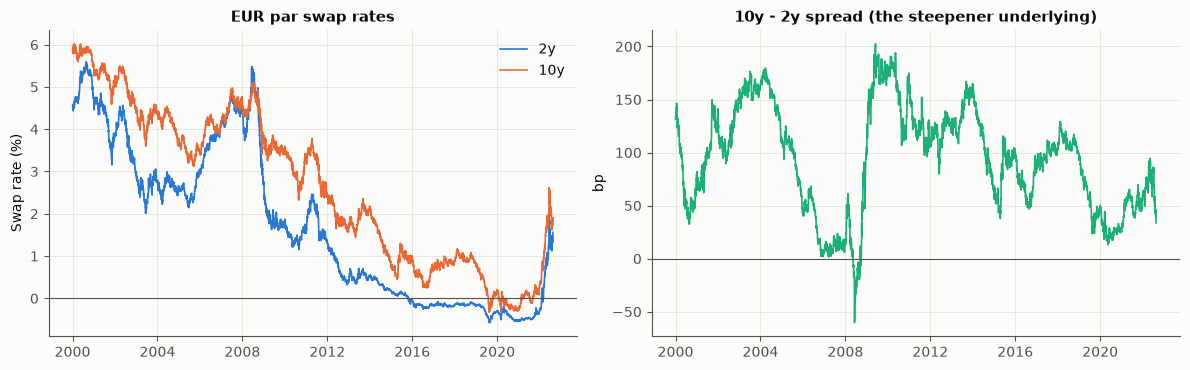

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.plot(rates.index, 100 * rates[2.0], label="2y", color=COLORS[0], lw=1.2)
ax.plot(rates.index, 100 * rates[10.0], label="10y", color=COLORS[1], lw=1.2)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("Swap rate (%)"); ax.set_title("EUR par swap rates"); ax.legend()
ax = axes[1]
spread = 1e4 * (rates[10.0] - rates[2.0])
ax.plot(spread.index, spread, color=COLORS[2], lw=1.2)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("bp"); ax.set_title("10y - 2y spread (the steepener underlying)")
fig.tight_layout(); save(fig, "history.png"); plt.show()

### 1.2 The curve at the valuation date
Pricing date: the last date of the file. The curve is bootstrapped from the 20 par swaps of that date (single-curve,
annual fixed leg, monotone convex interpolation) with the repository's `Bootstrapper`. It reprices them exactly.

YieldCurve(name='EUR swaps 2022-08-18', method='monotone_convex', pillars=20 from 1y to 50y) | max repricing error 1.7e-13bp


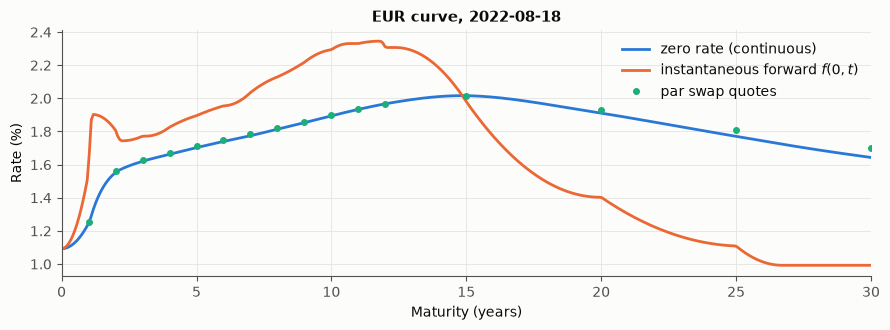

start (y),0,1,2,3,4,5,6,7,8,9
2y,1.562,1.824,1.787,1.842,1.913,1.974,2.055,2.152,2.242,2.32
10y,1.899,2.012,2.059,2.116,2.164,2.191,2.191,2.168,2.119,2.05
10y - 2y (bp),33.74,18.767,27.161,27.311,25.081,21.747,13.601,1.621,-12.332,-26.966


In [5]:
curve, bootstrapper = eur_curve(VALUATION_DATE, rates)
print(f"{curve} | max repricing error {bootstrapper.max_residual_bp:.1e}bp")
t = np.linspace(0.05, 30, 400)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(t, 100 * curve.zero_rate(t), label="zero rate (continuous)")
ax.plot(t, 100 * curve.instantaneous_forward(t), label="instantaneous forward $f(0,t)$")
row = rates.loc[VALUATION_DATE]
ax.plot(row.index, 100 * row.values, "o", color=COLORS[2], ms=4, label="par swap quotes")
ax.set_xlim(0, 30); ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Rate (%)")
ax.set_title(f"EUR curve, {VALUATION_DATE}"); ax.legend()
fig.tight_layout(); save(fig, "curve.png"); plt.show()

fwd = pd.DataFrame({f"{n:g}y": [forward_swap(curve, T, n)[0] for T in range(10)] for n in (2, 10)},
                   index=pd.Index(range(10), name="start (y)"))
fwd["10y - 2y (bp)"] = 1e4 * (fwd["10y"] - fwd["2y"])
fwd[["2y", "10y"]] *= 100
fwd.round(3).T

The forward 10y-2y spread **turns negative for swaps starting after 7 years**: forward-looking, the curve flattens. A steepener therefore
pays a lot on the first coupons and relies on the volatility of the spread (the floor) on the later ones.

### 1.3 Historical dynamics: vols, correlation, principal components

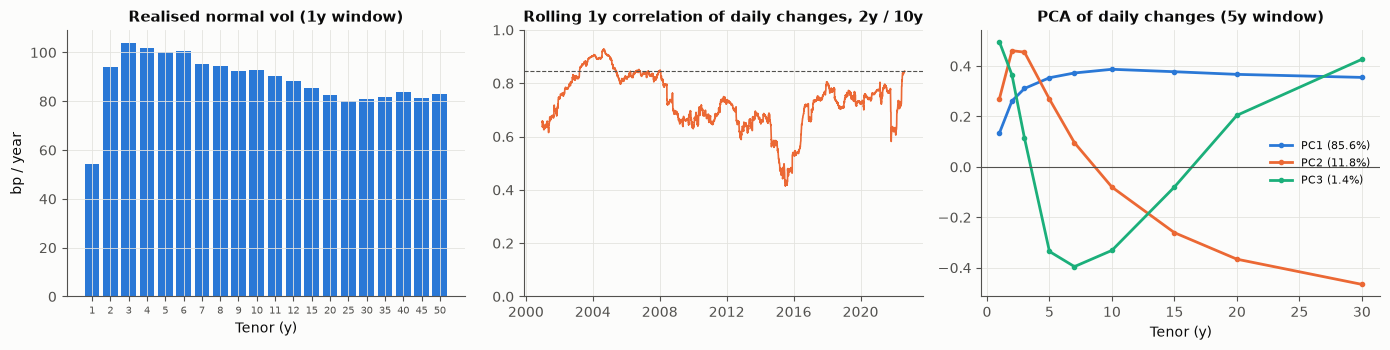

Correlation of daily changes 2y / 10y over the last year : 0.845 | variance explained by 1, 2, 3 factors : [85.6 97.4 98.8]%


In [6]:
vols = realised_normal_vols(rates, VALUATION_DATE, 252)
rho_hist = change_correlation(rates, 2.0, 10.0, VALUATION_DATE, 252)
rolling = change_correlation(rates, 2.0, 10.0, window=252, rolling=True)
explained, loadings = pca(rates, VALUATION_DATE)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
ax = axes[0]
ax.bar([f"{t:g}" for t in vols.index], 1e4 * vols.values, color=COLORS[0])
ax.set_xlabel("Tenor (y)"); ax.set_ylabel("bp / year"); ax.set_title("Realised normal vol (1y window)")
ax.tick_params(axis="x", labelsize=7)
ax = axes[1]
ax.plot(rolling.index, rolling, color=COLORS[1], lw=1.2)
ax.axhline(rho_hist, color=MUTED, lw=0.8, ls="--")
ax.set_title("Rolling 1y correlation of daily changes, 2y / 10y"); ax.set_ylim(0, 1)
ax = axes[2]
for k, c in enumerate(loadings.columns):
    ax.plot(loadings.index, loadings[c], "o-", ms=3, label=f"{c} ({100 * explained[k]:.1f}%)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel("Tenor (y)"); ax.set_title("PCA of daily changes (5y window)"); ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "historical.png"); plt.show()
print(f"Correlation of daily changes 2y / 10y over the last year : {rho_hist:.3f} | "
      f"variance explained by 1, 2, 3 factors : {np.round(100 * np.cumsum(explained[:3]), 1)}%")

One factor (level) explains about 86% of the daily variance and two factors explain about 97%. The second factor
(slope) is exactly the risk of a steepener: **at least two factors are needed**.

## 2. Volatility inputs (proxy and assumptions)

- **ATM normal vols**: realised vol of the tenor's spot swap rate over the year before the pricing date, used for
  every expiry (a proxy: the data contain no option prices).
- **Smile**: normal SABR ($\beta = 0$, negative rates allowed), $\alpha$ fitted to the ATM vol, $\rho$ and $\nu$
  illustrative.

historical proxy (252d realised vols to 2022-08-18) | SABR : {'rho': 0.1, 'nu': 0.3}


tenor (y),1,2,5,10,15,20
expiry (y),,,,,,
1,54.5,94.2,100.3,92.8,85.2,82.4
2,54.5,94.2,100.3,92.8,85.2,82.4
3,54.5,94.2,100.3,92.8,85.2,82.4
5,54.5,94.2,100.3,92.8,85.2,82.4
7,54.5,94.2,100.3,92.8,85.2,82.4
10,54.5,94.2,100.3,92.8,85.2,82.4


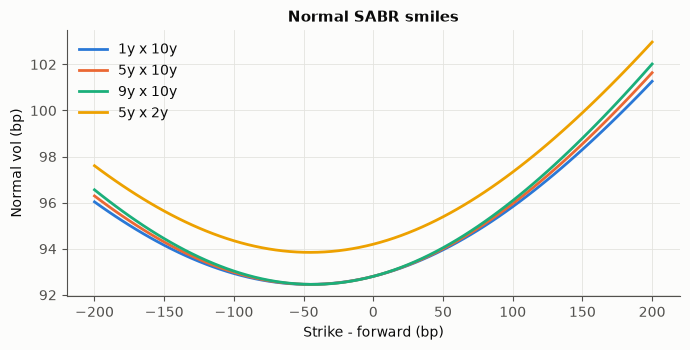

In [7]:
vol_grid = historical_swaption_vols(rates, VALUATION_DATE)
smile = sabr_smile(vol_grid)
print(vol_grid.name, "| SABR :", ILLUSTRATIVE_SABR)
display(vol_grid.to_frame().mul(1e4).round(1).rename_axis(index="expiry (y)", columns="tenor (y)"))

fig, ax = plt.subplots(figsize=(7, 3.6))
for (e, n), c in zip([(1, 10), (5, 10), (9, 10), (5, 2)], COLORS):
    S0 = forward_swap(curve, e, n)[0]
    K = S0 + np.linspace(-0.02, 0.02, 81)
    ax.plot(1e4 * (K - S0), 1e4 * smile(e, n, S0).normal_vol(K), color=c, label=f"{e}y x {n}y")
ax.set_xlabel("Strike - forward (bp)"); ax.set_ylabel("Normal vol (bp)"); ax.set_title("Normal SABR smiles")
ax.legend(); fig.tight_layout(); save(fig, "smiles.png"); plt.show()

## 3. CMS convexity by static replication

Under the annuity measure, $S$ is a martingale. A payoff paid at $T_p$ is valued with the annuity mapping
$P(T,T_p)/A(T) \approx G(S) = aS + b$ (linear terminal swap rate model, slope from a Gaussian model with mean
reversion $\kappa$). This gives
$$
\mathbb{E}^{T_p}[S(T)] = \frac{a\,\mathbb{E}^A[S^2] + b\,S_0}{G(S_0)}, \qquad
\mathbb{E}^A[S^2] = S_0^2 + 2\int_{S_0}^{\infty} C(k)\,dk + 2\int_{-\infty}^{S_0} P(k)\,dk .
$$
With a flat normal vol it reduces to $S_0 + a\,\sigma_N^2 T / G(S_0)$ (the Bachelier column). The steepener fixes at
$T$ and pays at $T + 1$, so the adjustment also contains a **timing** part.

In [8]:
replication = CMSReplication(curve, smile, mean_reversion=0.03, n_std=5)
rows = []
for T in range(1, 10):
    for n in (2, 10):
        S0 = forward_swap(curve, T, n)[0]
        rows.append({"fixing": T, "tenor": n, "forward (%)": 100 * S0,
                     "CA paid at T (bp)": 1e4 * replication.convexity_adjustment(T, n),
                     "CA paid at T+1 (bp)": 1e4 * replication.convexity_adjustment(T, n, T + 1),
                     "Bachelier CA, T+1 (bp)": 1e4 * (replication.cms_rate_bachelier(T, n, vol_grid.vol(T, n), T + 1) - S0)})
ca = pd.DataFrame(rows)
ca.pivot(index="fixing", columns="tenor", values=["CA paid at T+1 (bp)", "Bachelier CA, T+1 (bp)"]).round(2)

CA paid at T+1 (bp)       Bachelier CA, T+1 (bp)      
tenor                   2     10                     2     10
fixing                                                       
1                     0.44  3.87                   0.43  3.75
2                     0.91     8                   0.85   7.5
3                     1.41  12.4                   1.28 11.22
4                     1.95 17.12                    1.7 14.92
5                     2.53 22.19                   2.12  18.6
6                     3.16 27.63                   2.54 22.26
7                     3.83 33.51                   2.96 25.91
8                     4.56 39.87                   3.38 29.59
9                     5.34 46.79                    3.8 33.29

In [9]:
# Model risk of the replication itself : truncation of the wings and mean reversion of the mapping (CMS 10y, 9y -> 10y)
rows = {}
for n_std in (3, 4, 5, 6, 8):
    rows[f"n_std = {n_std}"] = {f"kappa = {k:g}": 1e4 * CMSReplication(curve, smile, k, n_std).convexity_adjustment(9, 10, 10)
                                for k in (0.0001, 0.03, 0.1)}
pd.DataFrame(rows).T.round(2)

,kappa = 0.0001,kappa = 0.03,kappa = 0.1
n_std = 3,42.81,43.66,45.17
n_std = 4,44.77,45.66,47.24
n_std = 5,45.87,46.79,48.41
n_std = 6,46.54,47.48,49.12
n_std = 8,47.27,48.22,49.89


The adjustment of the 10y CMS reaches about 45bp at 9 years (the 2y CMS stays below 6bp): it **steepens the
CMS forward spread** and therefore increases the steepener's value. The SABR wings add about 40% on top of the
flat-vol (Bachelier) adjustment at long expiries. The table above shows that the result depends on the strike
cut-off: the SABR expansion has heavy wings, and $\mathbb{E}^A[S^2]$ only converges because of the truncation.
This is a known weakness of CMS replication with SABR.

## 4. Market approach: replicated CMS forwards and a Gaussian spread

The note: 10 years, annual coupons, $4\times(\text{CMS}_{10} - \text{CMS}_2)$, floor 0%, cap 5%, notional 100,
capital protected. Each spread is taken Gaussian, centred on the replicated CMS forwards, with the ATM normal vols
and a correlation $\rho$. The floor and the cap are then Bachelier options on the spread.

In [10]:
note = CMSSteepener(maturity=10, long_tenor=10, short_tenor=2, leverage=4.0, margin=0.0, floor=0.0, cap=0.05)
market = price_replication_copula(note, replication, vol_grid, rho_hist)
print(f"{note} | rho = {rho_hist:.3f}")
print(f"Price {market['price']:.4f} = coupons {market['coupons']:.4f} + redemption {market['redemption']:.4f}")
cols = ["fixing", "forward long", "forward short", "CA long (bp)", "CA short (bp)", "spread vol (bp)",
        "expected coupon rate", "PV"]
market["table"][cols].round(5)

CMSSteepener(10y steepener 4 x (CMS10y - CMS2y) + 0bp, floor 0%, cap 5%, N=100) | rho = 0.845
Price 99.7952 = coupons 17.0540 + redemption 82.7412


,fixing,forward long,forward short,CA long (bp),CA short (bp),spread vol (bp),expected coupon rate,PV
payment,,,,,,,,
1,0,0.01899,0.01562,0,0,0,0.0135,1.33289
2,1,0.02012,0.01824,3.8721,0.43878,52.0547,0.0133,1.28954
3,2,0.02059,0.01787,7.99915,0.90794,52.0547,0.0183,1.74345
4,3,0.02116,0.01842,12.4034,1.40998,52.0547,0.0201,1.88039
5,4,0.02164,0.01913,17.1205,1.94932,52.0547,0.02101,1.92929
6,5,0.02191,0.01974,22.1857,2.53062,52.0547,0.02157,1.943
7,6,0.02191,0.02055,27.6333,3.15653,52.0547,0.02135,1.8854
8,7,0.02168,0.02152,33.5077,3.83043,52.0547,0.02067,1.78749
9,8,0.02119,0.02242,39.8735,4.5566,52.0547,0.01986,1.68098


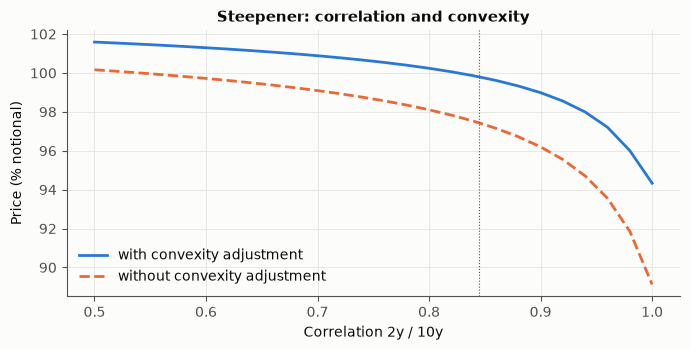

d price / d rho at rho_hist : -11.14 per unit of correlation | value of the convexity adjustment : 2.37


In [11]:
rhos = np.linspace(0.5, 1.0, 26)
prices = [price_replication_copula(note, replication, vol_grid, r)["price"] for r in rhos]
no_ca = CMSReplication(curve, smile, n_std=0.0)          # n_std = 0 : no convexity adjustment
prices_no_ca = [price_replication_copula(note, no_ca, vol_grid, r)["price"] for r in rhos]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(rhos, prices, color=COLORS[0], label="with convexity adjustment")
ax.plot(rhos, prices_no_ca, color=COLORS[1], ls="--", label="without convexity adjustment")
ax.axvline(rho_hist, color=MUTED, lw=0.8, ls=":")
ax.set_xlabel("Correlation 2y / 10y"); ax.set_ylabel("Price (% notional)")
ax.set_title("Steepener: correlation and convexity"); ax.legend()
fig.tight_layout(); save(fig, "correlation_sensitivity.png"); plt.show()
print(f"d price / d rho at rho_hist : {np.gradient(prices, rhos)[np.argmin(abs(rhos - rho_hist))]:.2f} per unit of correlation | "
      f"value of the convexity adjustment : {market['price'] - price_replication_copula(note, no_ca, vol_grid, rho_hist)['price']:.2f}")

The steepener is **short correlation**: lower correlation means a more volatile spread and a more valuable floor.
The convexity adjustment adds about 2.4 points of notional. A model for this product must therefore both
fit the smile (convexity) and control the decorrelation of the two rates.

## 5. Hull-White 1F: the baseline that cannot price a spread

Calibrated with the existing `HullWhite.calibrate` on ATM 2y and 10y swaptions (proxy vols).

In [12]:
market_pricer = RatePricer(curve, swaption_vols=vol_grid, model="bachelier")
atm = lambda e, n: Swaption(e, n, forward_swap(curve, e, n)[0], notional=1.0)
hw_swaptions = [atm(e, n) for e in (1, 3, 5, 7, 9) for n in (2, 10)]
hw = HullWhite(curve)
hw_calibration = hw.calibrate(market_pricer, hw_swaptions)
print(hw, {k: round(v, 2) for k, v in hw_calibration.items() if "bp" in k})
t0 = time.time()
results = {"HW1F": price_mc(hw, note, N_PATHS, SEED)}
print(f"HW1F price {results['HW1F']['price']:.4f} (s.e. {results['HW1F']['stderr']:.4f}) in {time.time() - t0:.1f}s")
results["HW1F"]["table"][["CA long (bp)", "CA short (bp)", "corr long/short", "expected coupon rate"]].round(4)

HullWhite(a=0.0031, sigma=93.3bp) {'RMSE (bp of normal vol)': 0.22, 'max error (bp)': 0.41}
HW1F price 92.8863 (s.e. 0.0113) in 0.1s


,CA long (bp),CA short (bp),corr long/short,expected coupon rate
payment,,,,
1,0,0,NaN,0.0135
2,3.7054,0.432,1,0.0088
3,7.3631,0.8521,1,0.0135
4,10.9952,1.2678,1,0.0148
5,14.6514,1.7236,1,0.0152
6,18.3355,2.2117,1,0.0151
7,21.9617,2.6271,1,0.0132
8,25.6635,3.0994,1,0.0097
9,29.4306,3.628,1,0.0054


With one factor, the two CMS rates are perfectly correlated (correlation 1.000 in the table). The spread is then
nearly deterministic, the floor is almost worthless, and the forward inversion after 7 years kills the late coupons.
The price lies far below the market approach.

## 6. G2++ / Hull-White two-factor

$r = x + y + \varphi$ with two correlated Ornstein-Uhlenbeck factors. Swaption vols and terminal swap-rate
correlations are computed in closed form with the frozen-gradient approximation. The calibration targets are the ATM
proxy vols (tenors 2y, 5y, 10y) and, optionally, the historical 2y/10y correlation at 1, 5 and 9 years.

In [13]:
corr_targets = [(e, 2, 10, rho_hist) for e in (1, 5, 9)]
calibrations = {}
g2_vol_only = G2pp(curve)
calibrations["vols only"] = g2_vol_only.calibrate(vol_grid, tenors=[2, 5, 10])
g2 = G2pp(curve)
calibrations["vols + correlation"] = g2.calibrate(vol_grid, tenors=[2, 5, 10], correlation_targets=corr_targets,
                                                  correlation_weight=3.0)
pd.DataFrame(calibrations).T.astype(float).round(4)

,a,b,sigma,eta,rho,RMSE (bp of normal vol),max error (bp),corr 1y 2y/10y,corr 5y 2y/10y,corr 9y 2y/10y
vols only,0.0225,0.451,0.0113,0.0033,-0.999,2.7422,5.2378,NaN,NaN,NaN
vols + correlation,0.0045,0.0378,0.0427,0.05,-0.9784,6.973,13.9308,0.8568,0.8526,0.8875


**Vol-only calibration is degenerate**: $\rho \to -1$, the two factors collapse into one and the 2y/10y
correlation is 1. Reaching the historical correlation of about 0.85 needs two **large, almost perfectly
anti-correlated** factors ($\sigma, \eta \approx 430$-$500$bp, $\rho \approx -0.98$), at the cost of a worse vol fit.
This is the well-known G2++ behaviour: the decorrelation comes from the difference of two large factors.

Monte Carlo checks: the martingale test on discount factors, and swaption vols by Monte Carlo against the closed-form
approximation.

In [14]:
times = np.array([1.0, 5.0, 10.0, 20.0])
display(martingale_test(g2, times, 100_000))
rows = {}
for e, n in [(1, 10), (5, 2), (5, 10), (9, 10)]:
    S0 = forward_swap(curve, e, n)[0]
    mc, _ = mc_swaption_vols(g2, e, n, [S0 - 0.01, S0, S0 + 0.01], 100_000, 3)
    rows[f"{e}y x {n}y"] = {"proxy ATM": 1e4 * vol_grid.vol(e, n), "closed form": 1e4 * g2.swaption_normal_vol(e, n),
                            "MC K-100bp": 1e4 * mc[0], "MC ATM": 1e4 * mc[1], "MC K+100bp": 1e4 * mc[2]}
pd.DataFrame(rows).T.round(1)

T,1,5,10,20
error (bp),-0,-0.32,-0.34,5.22
s.e. (bp),0,0.12,0.73,4.75


,proxy ATM,closed form,MC K-100bp,MC ATM,MC K+100bp
1y x 10y,92.8,87.6,87,87.6,88.1
5y x 2y,94.2,95.5,95.4,95.8,96.3
5y x 10y,92.8,91.7,91,91.3,91.6
9y x 10y,92.8,103.4,102.1,102.7,102.8


In [15]:
t0 = time.time()
results["G2++"] = price_mc(g2, note, N_PATHS, SEED)
print(f"G2++ price {results['G2++']['price']:.4f} (s.e. {results['G2++']['stderr']:.4f}) in {time.time() - t0:.1f}s")
results["G2++"]["table"][["CA long (bp)", "CA short (bp)", "corr long/short", "expected coupon rate",
                          "martingale error (bp)"]].round(4)

G2++ price 99.3811 (s.e. 0.0261) in 0.1s


,CA long (bp),CA short (bp),corr long/short,expected coupon rate,martingale error (bp)
payment,,,,,
1,0.0001,0,NaN,0.0135,0.0027
2,3.2967,0.5248,0.8576,0.0136,0.0118
3,6.5264,0.9545,0.8525,0.0183,0.0385
4,9.8698,1.3716,0.8504,0.0198,0.0599
5,13.462,1.7212,0.85,0.0205,0.14
6,17.3752,2.0464,0.8564,0.0209,0.1898
7,21.8455,2.4748,0.8619,0.0206,0.2881
8,26.8006,2.7746,0.8707,0.0198,0.4658
9,32.4227,3.1789,0.8804,0.0189,0.695


## 7. Two-factor quasi-Gaussian (Cheyette) model with local and stochastic volatility

The Gaussian core is the calibrated G2++ (the two models coincide when $\beta = \varepsilon = 0$). The volatility is
multiplied by $m = \sqrt{z}\,\max(1 + \beta(x_1 + x_2), 0.05)$ with $dz = \theta(1-z)dt + \varepsilon\sqrt{z}\,dZ$.
$\beta$ (local vol skew), $\varepsilon$ (vol of variance) and a global vol scale are calibrated by Monte Carlo (common
random numbers) to the SABR smiles of the 2y x 10y, 5y x 10y and 5y x 2y swaptions at ATM $\pm$ 50 and 100bp.

In [16]:
strikes = np.array([-0.01, -0.005, 0.0, 0.005, 0.01])
smile_targets = []
for e, n in [(2, 10), (5, 10), (5, 2)]:
    S0 = forward_swap(curve, e, n)[0]
    smile_targets.append((e, n, S0 + strikes, smile(e, n, S0).normal_vol(S0 + strikes)))

t0 = time.time()
cheyette_lv = QuasiGaussian.from_g2(g2, dt=1 / 12)
cal_lv = cheyette_lv.calibrate_smile(smile_targets, names=("vol_scale", "beta"))
cheyette_sv = QuasiGaussian.from_g2(g2, dt=1 / 12)
cal_sv = cheyette_sv.calibrate_smile(smile_targets, names=("vol_scale", "beta", "epsilon"))
print(f"calibrated in {time.time() - t0:.0f}s")
print("LV    :", cheyette_lv, {k: round(v, 2) for k, v in cal_lv.items() if "bp" in k})
print("LV+SV :", cheyette_sv, {k: round(v, 2) for k, v in cal_sv.items() if "bp" in k})

calibrated in 17s
LV    : QuasiGaussian(d=2, kappa=[0.0045, 0.0378], sigma(bp)=[437.1, 512.3], beta=3.522, epsilon=0.000) {'RMSE (bp of normal vol)': 3.05, 'max error (bp)': 4.98}
LV+SV : QuasiGaussian(d=2, kappa=[0.0045, 0.0378], sigma(bp)=[448.4, 525.5], beta=3.556, epsilon=1.290) {'RMSE (bp of normal vol)': 3.01, 'max error (bp)': 4.43}


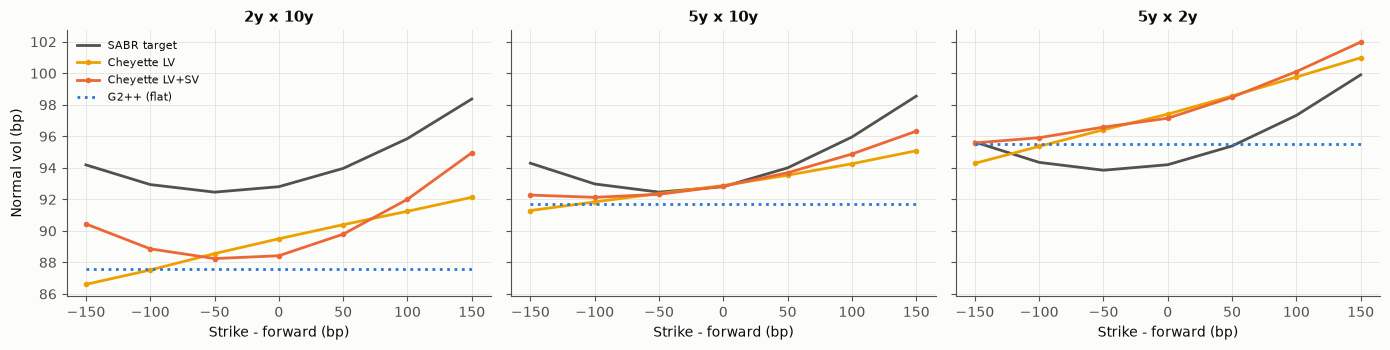

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (e, n, K, target) in zip(axes, smile_targets):
    S0 = forward_swap(curve, e, n)[0]
    grid = S0 + np.linspace(-0.015, 0.015, 7)
    ax.plot(1e4 * (grid - S0), 1e4 * smile(e, n, S0).normal_vol(grid), color=MUTED, label="SABR target")
    for model, name in [(cheyette_lv, "Cheyette LV"), (cheyette_sv, "Cheyette LV+SV")]:
        mc, _ = mc_swaption_vols(model, e, n, grid, 100_000, 11)        # independent seed
        ax.plot(1e4 * (grid - S0), 1e4 * mc, "o-", ms=3, color=MODEL_COLOR[name], label=name)
    ax.plot(1e4 * (grid - S0), np.full(len(grid), 1e4 * g2.swaption_normal_vol(e, n)), ls=":",
            color=MODEL_COLOR["G2++"], label="G2++ (flat)")
    ax.set_title(f"{e}y x {n}y"); ax.set_xlabel("Strike - forward (bp)")
axes[0].set_ylabel("Normal vol (bp)"); axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "cheyette_smiles.png"); plt.show()

In [18]:
display(martingale_test(cheyette_sv, times, 50_000))                # Euler, monthly steps
for model, name in [(cheyette_lv, "Cheyette LV"), (cheyette_sv, "Cheyette LV+SV")]:
    t0 = time.time()
    results[name] = price_mc(model, note, N_PATHS, SEED)
    print(f"{name} price {results[name]['price']:.4f} (s.e. {results[name]['stderr']:.4f}) in {time.time() - t0:.1f}s")
results["Cheyette LV+SV"]["table"][["CA long (bp)", "CA short (bp)", "corr long/short", "expected coupon rate",
                                    "martingale error (bp)"]].round(4)

T,1,5,10,20
error (bp),0.16,0.75,0.99,3.03
s.e. (bp),0.12,1.58,3.79,10.21


Cheyette LV price 99.7826 (s.e. 0.0214) in 0.3s
Cheyette LV+SV price 99.6571 (s.e. 0.0597) in 0.3s


,CA long (bp),CA short (bp),corr long/short,expected coupon rate,martingale error (bp)
payment,,,,,
1,0.0008,0.0006,NaN,0.0135,0.0395
2,3.7538,0.586,0.8605,0.0137,0.4242
3,7.2761,0.6914,0.856,0.0183,0.8054
4,11.0282,1.2078,0.8544,0.02,1.2997
5,15.0131,1.4421,0.8553,0.0208,1.5301
6,19.8631,2.5725,0.8599,0.0212,1.438
7,24.6632,3.0124,0.8694,0.0209,1.5529
8,29.6789,3.0982,0.8785,0.0202,2.0666
9,35.1969,2.9729,0.8883,0.0194,3.1496


The local and stochastic volatility reproduce the **shape** of the smile (skew and curvature). The level error
inherited from the Gaussian core is a few bp, because that core is a compromise between vols and correlation. The
smile increases the 10y CMS adjustment compared with G2++, in line with the replication of Section 3.

## 8. SABR-LMM

Annual forwards on a 20-year grid (the annual EUR fixed leg makes swap rates exact baskets of forwards), normal
SABR-LMM ($\beta = 0$) with a common volatility factor:
$dF_j = \sigma_j(t)\,V\,dW_j$, $dV = \nu V dZ$, Rebonato's abcd volatility and
$\rho_{ij} = \rho_\infty + (1-\rho_\infty)e^{-\lambda|T_i - T_j|}$.
$\nu$ and $\rho_{sv}$ are set to the SABR smile parameters (each swap rate is then approximately a SABR with the same
$\nu$). abcd and the correlation are calibrated with Rebonato's frozen weights to the ATM vols and the correlation
targets. The plain LMM ($\nu = 0$) is calibrated in the same way.

In [19]:
lmm_calibrations = {}
sabr_lmm = SABRLMM(curve, 20, nu=ILLUSTRATIVE_SABR["nu"], rho_sv=ILLUSTRATIVE_SABR["rho"])
lmm_calibrations["SABR-LMM"] = sabr_lmm.calibrate(vol_grid, tenors=[2, 5, 10], correlation_targets=corr_targets)
lmm = SABRLMM(curve, 20)
lmm_calibrations["LMM"] = lmm.calibrate(vol_grid, tenors=[2, 5, 10], correlation_targets=corr_targets)
print(sabr_lmm); print(lmm)
pd.DataFrame(lmm_calibrations).T.astype(float).round(4)

SABRLMM(N=20, tau=1, abcd=(0.0004, 0.0007, 0.193, 0.0085), rho_inf=0.000, decay=0.064, nu=0.300, rho_sv=+0.100, beta=0)
SABRLMM(N=20, tau=1, abcd=(-0.0013, 0.0005, 0.254, 0.0101), rho_inf=0.000, decay=0.071, nu=0.000, rho_sv=+0.000, beta=0)


,a,b,c,d,rho_inf,decay,RMSE (bp of normal vol),max error (bp),corr 1y 2y/10y,corr 5y 2y/10y,corr 9y 2y/10y
SABR-LMM,0.0004,0.0007,0.1928,0.0085,0,0.064,4.28,9.4713,0.885,0.889,0.8894
LMM,-0.0013,0.0005,0.254,0.0101,0,0.0713,3.4709,7.0164,0.8688,0.8735,0.874


In [20]:
display(martingale_test(sabr_lmm, times, 50_000))                   # spot measure, quarterly steps
rows = {}
for e, n in [(1, 10), (5, 2), (5, 10), (9, 10)]:
    S0 = forward_swap(curve, e, n)[0]
    K = np.array([S0 - 0.01, S0, S0 + 0.01])
    mc, _ = mc_swaption_vols(sabr_lmm, e, n, K, 50_000, 3)
    target = smile(e, n, S0).normal_vol(K)
    rows[f"{e}y x {n}y"] = {"SABR K-100": 1e4 * target[0], "MC K-100": 1e4 * mc[0], "SABR ATM": 1e4 * target[1],
                            "frozen weights ATM": 1e4 * sabr_lmm.swaption_normal_vol(e, n), "MC ATM": 1e4 * mc[1],
                            "SABR K+100": 1e4 * target[2], "MC K+100": 1e4 * mc[2]}
pd.DataFrame(rows).T.round(1)

T,1,5,10,20
error (bp),0,-0.35,-5.86,-3.2
s.e. (bp),0,0.87,3.57,18.02


,SABR K-100,MC K-100,SABR ATM,frozen weights ATM,MC ATM,SABR K+100,MC K+100
1y x 10y,92.9,88.9,92.8,89.4,89.4,95.8,91.3
5y x 2y,94.3,99.9,94.2,100.2,99.7,97.3,102.2
5y x 10y,93,90.8,92.8,91.9,90.4,96,93.3
9y x 10y,93,90.7,92.8,93.1,90.9,96.1,93.8


In [21]:
for model, name in [(lmm, "LMM"), (sabr_lmm, "SABR-LMM")]:
    t0 = time.time()
    results[name] = price_mc(model, note, N_PATHS, SEED)
    print(f"{name} price {results[name]['price']:.4f} (s.e. {results[name]['stderr']:.4f}) in {time.time() - t0:.1f}s")
results["SABR-LMM"]["table"][["CA long (bp)", "CA short (bp)", "corr long/short", "expected coupon rate",
                              "martingale error (bp)"]].round(4)

LMM price 99.1042 (s.e. 0.0219) in 0.9s
SABR-LMM price 98.2057 (s.e. 0.0502) in 1.0s


,CA long (bp),CA short (bp),corr long/short,expected coupon rate,martingale error (bp)
payment,,,,,
1,-0,0,NaN,0.0135,0
2,3.5255,0.4633,0.886,0.0122,-0.0395
3,7.0091,0.5974,0.8885,0.0172,0.2957
4,11.2836,1.2186,0.8885,0.0189,0.5184
5,15.5007,1.5514,0.8915,0.0196,1.1166
6,20.2469,2.3639,0.8911,0.0199,1.6983
7,25.5623,3.9518,0.8921,0.0192,1.2521
8,30.136,3.7842,0.8944,0.018,1.4884
9,35.8361,4.1359,0.897,0.0166,2.1535


## 9. Comparison of the models

In [22]:
models = {"HW1F": hw, "G2++": g2, "Cheyette LV": cheyette_lv, "Cheyette LV+SV": cheyette_sv, "LMM": lmm,
          "SABR-LMM": sabr_lmm}
summary = {"Replication + Gaussian spread": {"price": market["price"], "s.e.": 0.0,
                                             "CA 10y at 9y (bp)": market["table"]["CA long (bp)"].iloc[-1],
                                             "CA 2y at 9y (bp)": market["table"]["CA short (bp)"].iloc[-1],
                                             "corr 2y/10y at 5y": rho_hist}}
for name, res in results.items():
    tab = res["table"]
    summary[name] = {"price": res["price"], "s.e.": res["stderr"], "CA 10y at 9y (bp)": tab["CA long (bp)"].iloc[-1],
                     "CA 2y at 9y (bp)": tab["CA short (bp)"].iloc[-1], "corr 2y/10y at 5y": tab["corr long/short"].iloc[5]}
summary = pd.DataFrame(summary).T
summary.round(4)

,price,s.e.,CA 10y at 9y (bp),CA 2y at 9y (bp),corr 2y/10y at 5y
Replication + Gaussian spread,99.7952,0,46.7877,5.3389,0.8451
HW1F,92.8863,0.0113,33.0833,4.0427,1
G2++,99.3811,0.0261,38.7564,3.5357,0.8564
Cheyette LV,99.7826,0.0214,39.5298,3.2528,0.8586
Cheyette LV+SV,99.6571,0.0597,41.7687,3.1749,0.8599
LMM,99.1042,0.0219,33.4449,4.1054,0.8757
SABR-LMM,98.2057,0.0502,41.3492,4.5624,0.8911


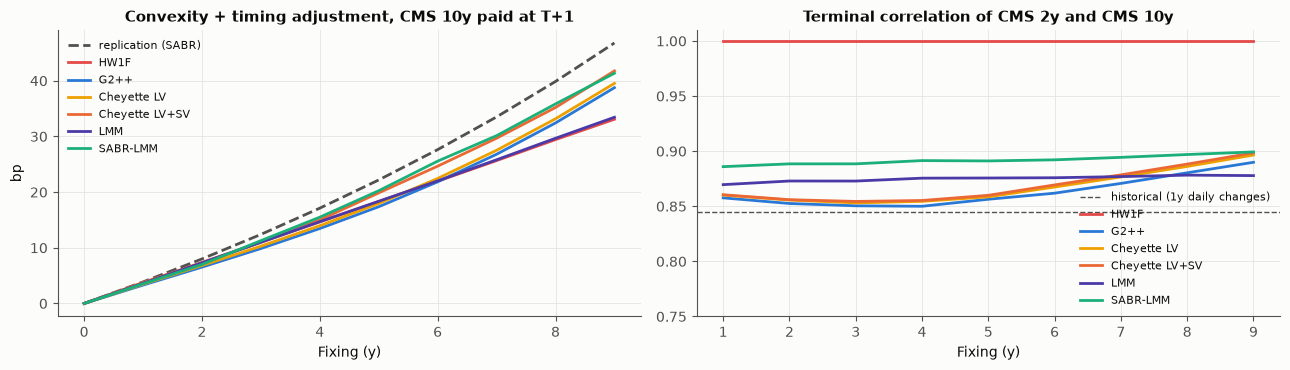

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
fix = note.fixing_times
ax = axes[0]
ax.plot(fix, market["table"]["CA long (bp)"].values, color=MODEL_COLOR["Replication + Gaussian spread"], ls="--",
        label="replication (SABR)")
for name, res in results.items():
    ax.plot(fix, res["table"]["CA long (bp)"].values, color=MODEL_COLOR[name], label=name)
ax.set_xlabel("Fixing (y)"); ax.set_ylabel("bp"); ax.set_title("Convexity + timing adjustment, CMS 10y paid at T+1")
ax.legend(fontsize=8)
ax = axes[1]
ax.axhline(rho_hist, color=MUTED, ls="--", lw=1, label="historical (1y daily changes)")
for name, res in results.items():
    ax.plot(fix[1:], res["table"]["corr long/short"].values[1:], color=MODEL_COLOR[name], label=name)
ax.set_xlabel("Fixing (y)"); ax.set_title("Terminal correlation of CMS 2y and CMS 10y"); ax.set_ylim(0.75, 1.01)
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "model_comparison.png"); plt.show()

## 10. Fair margin and sensitivities

**Fair margin**: the margin $m$ that prices the note at par (100). It is solved on fixed paths: the paths do not
depend on $m$, so `simulate_cms` is run once per model.

In [24]:
margins = {"Replication + Gaussian spread": fair_margin(note, lambda n: price_replication_copula(n, replication, vol_grid, rho_hist)["price"])}
for name, model in models.items():
    paths = simulate_cms(model, note, N_PATHS, SEED)
    margins[name] = fair_margin(note, lambda n: price_mc(model, n, paths=paths)["price"])
summary["fair margin (bp)"] = 1e4 * pd.Series(margins)
summary[["price", "s.e.", "fair margin (bp)"]].round(3)

,price,s.e.,fair margin (bp)
Replication + Gaussian spread,99.795,0,4.522
HW1F,92.886,0.011,78.38
G2++,99.381,0.026,13.491
Cheyette LV,99.783,0.021,4.739
Cheyette LV+SV,99.657,0.06,7.345
LMM,99.104,0.022,18.926
SABR-LMM,98.206,0.05,35.404


In [25]:
# Parallel delta and correlation sensitivity in G2++ : curve bumped +-1bp (model parameters unchanged) ;
# correlation : rho_hist +-0.05 targets, recalibrated
rows = {}
up, down = g2.with_curve(curve.shifted(1.0)), g2.with_curve(curve.shifted(-1.0))
p_up, p_dn = price_mc(up, note, N_PATHS, SEED)["price"], price_mc(down, note, N_PATHS, SEED)["price"]
rows["G2++ DV01 (per bp, % notional)"] = (p_up - p_dn) / 2
for shift in (-0.05, 0.05):
    m = G2pp(curve)
    m.calibrate(vol_grid, tenors=[2, 5, 10], correlation_targets=[(e, 2, 10, rho_hist + shift) for e in (1, 5, 9)],
                correlation_weight=3.0)
    rows[f"G2++ price, correlation target {rho_hist + shift:.3f}"] = price_mc(m, note, N_PATHS, SEED)["price"]
rows["G2++ price, base"] = results["G2++"]["price"]
pd.Series(rows, name="value").to_frame().round(4)

,value
"G2++ DV01 (per bp, % notional)",-0.0929
"G2++ price, correlation target 0.795",99.96
"G2++ price, correlation target 0.895",98.5002
"G2++ price, base",99.3811
